# Firing rates (KS4)

## Setup

3. Download with notebooks/0_download_sortings.ipynb

In [1]:
%load_ext autoreload
%autoreload 2
from matplotlib import pyplot as plt
import numpy as np
import os
import warnings
import pandas as pd 

warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings("ignore")

# SET PROJECT PATH

PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias-paper"
os.chdir(PROJ_PATH)
from src.nodes.utils import get_config, savefig
from src.nodes.validation import firing_rate as fr
from src.nodes.validation.npx_probe import firing_rate as fr_npx

# SETUP EXPERIMENTS

# setup kilosort4 sorting paths
SORTED_PATH_nv = "dataset/01_intermediate/sorting/marques/SortingKS4_10m_rtx5090"   # first 10 min of the whole-length sorting
SORTED_PATH_ns = "dataset/01_intermediate/sorting/npx_spont_v100/SortingKS4_10m"   # Tesla V100
SORTED_PATH_ne = "dataset/01_intermediate/sorting/npx_evoked_40khz/SortingKS4_10m"   # evoked regime sampled at 40 kHz, first 10 minutes
SORTED_PATH_nb = "dataset/01_intermediate/sorting/buccino/SortingKS4_10m"

# PARAMETERS
SINGLE_UNIT = True
layers = ["L1", "L2/3", "L4", "L5", "L6"]

# SETUP PLOT 

# set lognormal plot parameters
log_x_min = -3.0
log_x_max = 3.0
nbins = 30

# IF you don't want to use the feature, set the value to 1E100
t_dec = 1^100 # seconds until experimenter decides a cell is silent

cl = dict()
cl["COLOR_NV"] = [0.6, 0.6, 0.6]
cl["COLOR_NS"] = [0.9, 0.14, 0.15]
cl["COLOR_NB"] = [0.22, 0.5, 0.72] # blue
cl["COLOR_NE"] = [1, 0.49, 0] # orange
cl["COLOR_HV"] = "k" # black
cl["COLOR_HS"] = np.array([26, 152, 80]) / 255 # green

# axes
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5 # typically between 0.5 and 1
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["xtick.minor.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["ytick.major.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["ytick.minor.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1

# legend
legend_cfg = {"frameon": False, "handletextpad": 0.5}
tight_layout_cfg = {"pad": 0.001}
LG_FRAMEON = False              # no legend frame

savefig_cfg = {"transparent":True, "dpi": 400}

In [2]:
import os, sys
sys.path.insert(0, os.getcwd())     # the repository
from src.nodes import figure_style
figure_style.apply()

## Get metadata

In [3]:
# get unit metadata
df_nv = fr.get_sorted_unit_meta(SORTED_PATH_nv)
df_ns = fr.get_sorted_unit_meta(SORTED_PATH_ns)
df_ne = fr.get_sorted_unit_meta(SORTED_PATH_ne)
df_nb = fr.get_synth_unit_meta(SORTED_PATH_nb)

# keep units in cortex
df_nv = df_nv[np.isin(df_nv["layer"], ["L1", "L2/3", "L4", "L5", "L6"])]
df_ns = df_ns[np.isin(df_ns["layer"], ["L1", "L2/3", "L4", "L5", "L6"])]
df_ne = df_ne[np.isin(df_ne["layer"], ["L1", "L2/3", "L4", "L5", "L6"])]

# unit-test: check all in cortex
assert all(
    np.isin(np.sort(df_nv["layer"].unique()), ["L1", "L2/3", "L4", "L5", "L6"])
), "nor all in cortex"
assert all(
    np.isin(np.sort(df_ns["layer"].unique()), ["L1", "L2/3", "L4", "L5", "L6"])
), "nor all in cortex"
assert all(
    np.isin(np.sort(df_nv["layer"].unique()), ["L1", "L2/3", "L4", "L5", "L6"])
), "nor all in cortex"

## Curate/or not

In [4]:
if SINGLE_UNIT:
    df_nv = df_nv[df_nv["kslabel"] == "good"]
    df_ns = df_ns[df_ns["kslabel"] == "good"]
    df_ne = df_ne[df_ne["kslabel"] == "good"]
    df_nb = df_nb[df_nb["kslabel"] == "good"]

## Sorted units total

In [5]:
# reproducible - OK
print("M: total sorted unit:", df_nv.shape[0])
print("NS: total sorted unit:", df_ns.shape[0])
print("E: total sorted unit:", df_ne.shape[0])
print("S: total sorted unit:", df_nb.shape[0])

M: total sorted unit: 106
NS: total sorted unit: 257
E: total sorted unit: 273
S: total sorted unit: 377


## Plot firing rate variance

In [6]:
layers = ["L1", "L2/3", "L4", "L5", "L6"]
exps = ["M", "NS", "E", "S"]

In [7]:
def get_ci95(data):
    return 1.96 * np.nanstd(data) / np.sqrt(np.sum(~np.isnan(data)))

(4.2, -0.3)

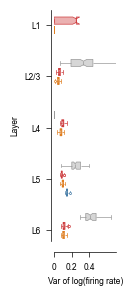

In [8]:
# setup figure
FIGSIZE = (0.8, 3)

# setup reproducible seed
SEED = 0

# setup plot
fig, ax = plt.subplots(1, figsize=FIGSIZE)

# plot
ax, df_var = fr_npx.plot_fr_std_stats_by_layer_vert(
    ax, df_nv, df_ns, df_ne, df_nb, layers, cl, seed=SEED
)

# format
ax.set_xticks([0, 0.2, 0.4], [0, 0.2, 0.4])
ax.set_xlim(
    [df_var["Var(log(firing rate))"].min(), df_var["Var(log(firing rate))"].max()]
)
ax.set_ylim((4.2, -0.3))

### Create source dataset

In [9]:
df_var.to_excel("figures/source_data/fig4c/fig4c.xlsx", index=False)
display(df_var)

,Var(log(firing rate)),experiment,layer,n_units
0,NaN,M,L1,0
527,0.000000,NS,L1,2
528,0.253368,NS,L1,2
529,0.000000,NS,L1,2
530,0.000000,NS,L1,2
...,...,...,...,...
931,0.125607,NS,L6,85
932,0.114242,NS,L6,85
933,0.118658,NS,L6,85
925,0.092272,NS,L6,85


### Load

In [10]:
# load source dataset
df = pd.read_excel("figures/source_data/fig4c/fig4c.xlsx")

### Re-plot

2026-11-07 17:40:01,010 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - maxp pruned


2026-11-07 17:40:01,011 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - LTSH dropped


2026-11-07 17:40:01,011 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - cmap pruned


2026-11-07 17:40:01,014 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - kern pruned


2026-11-07 17:40:01,014 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - post pruned


2026-11-07 17:40:01,015 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - PCLT dropped


... (41 outputs left out)

2026-11-07 17:40:01,029 - fontTools.subset - __init__.py - _prune_post_subset - INFO - glyf pruned


2026-11-07 17:40:01,029 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GDEF pruned to empty; dropped


2026-11-07 17:40:01,030 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GSUB pruned


2026-11-07 17:40:01,032 - fontTools.subset - __init__.py - _prune_post_subset - INFO - name pruned


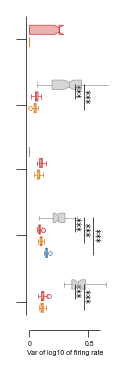

In [11]:
from src.nodes.validation import firing_rate_plots as frp

# plot from the source data
fig = frp.plot_source_data(df, "c")
fig.savefig("figures/source_data/fig4c/fig4c.svg", **savefig_cfg)
plt.show()